In [27]:
# Modules gotten from Lecture 6 regarding PINNs
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# Exercise X14.03

This exercise will develop a PINN strategy to discover the parameters of the four tank system, which is a nonlinear system of ODEs. The system is described as:

In [28]:
def four_tank_system(t, x, u, p):
    """Return dx/dt for the four-tank system.

    x: tank masses [g], shape (4,)
    u: pump flow rates [cm^3/s], shape (2,)
    p: parameters, shape (12,)
    """
    x = np.asarray(x, dtype=float).reshape(4)
    u = np.asarray(u, dtype=float).reshape(2)
    p = np.asarray(p, dtype=float).reshape(12)

    # Unpack parameters
    a = p[0:4]       # Pipe cross-sectional areas [cm^2]
    A = p[4:8]       # Tank cross-sectional areas [cm^2]
    gamma = p[8:10]  # Valve positions [-]
    g = p[10]        # Acceleration of gravity [cm/s^2]
    rho = p[11]      # Water density [g/cm^3]

    # Inflows
    qin = np.array([
        gamma[0] * u[0],
        gamma[1] * u[1],
        (1 - gamma[1]) * u[1],
        (1 - gamma[0]) * u[0],
    ])

    # Outflows
    x[x < 0] = 0 # Masses can't be negative
    h = x / (rho * A)
    qout = a * np.sqrt(2 * g * h)

    # Mass balances
    return rho * np.array([
        qin[0] + qout[2] - qout[0],
        qin[1] + qout[3] - qout[1],
        qin[2] - qout[2],
        qin[3] - qout[3],
    ])

The four tank system is a set of simple, nonlinear ODEs, which describe the flow of water through four tanks. It is assumed that the tank and pipe areas are known for all four tanks. Furthermore, the density of the liquid is also assumed to be known. The unknown variables that the PINN should estimate is the valve openings, gamma1 and gamma2.

The known parameters are defined together with the inlet flows.
The "unknown" parameters will be defined as gamma1 = 0.6 and gamma2 = 0.7.

In [29]:
# Parameters
a1 = 1.2272  # [cm^2] Area of outlet pipe 1
a2 = 1.2272  # [cm^2] Area of outlet pipe 2
a3 = 1.2272  # [cm^2] Area of outlet pipe 3
a4 = 1.2272  # [cm^2] Area of outlet pipe 4

A1 = 380.1327  # [cm^2] Cross-sectional area of tank 1
A2 = 380.1327  # [cm^2] Cross-sectional area of tank 2
A3 = 380.1327  # [cm^2] Cross-sectional area of tank 3
A4 = 380.1327  # [cm^2] Cross-sectional area of tank 4

ap = np.array([a1, a2, a3, a4])  # [cm^2] Pipe cross-sectional areas
At = np.array([A1, A2, A3, A4])  # [cm^2] Tank cross-sectional areas

gamma1 = 0.6  # Flow distribution constant for valve 1
gamma2 = 0.7  # Flow distribution constant for valve 2

gam = np.array([gamma1, gamma2])

g = 981   # [cm/s^2] Acceleration of gravity
rho = 1.00  # [g/cm^3] Density of water

rhoA = rho*At

# Parameter vector, in the order expected by four_tank_system
p = np.array([a1, a2, a3, a4, A1, A2, A3, A4, gamma1, gamma2, g, rho])

To generate training data for the PINN, the system is solved using the ode solver "scipy.integrate.solve_ivp". Multiple scenarios are simulated, to train the PINN on different conditions. The PINN will takes time and inlet flows as inputs and will output the states, masses in all four tanks. To simplify the problem, it is therefore assumed that the initial condition is always that the tanks are empty. One could make the PINN more advanced, and also give the initial condition as inlet.

To generate training data, 10 different scenarios are tested, where the inlet flowrate of F1 and F2 are randomly chosen to be between 50 and 150 cm^3 / s. The system is solved for each of these conditions for 10 min. A sampling time of 1 s is used.

After each scenario is simulated, the data is processed, to fit the PINN. During construction of the PINN, it was seen that the data was not very well scaled, so in order to mitigate scaling problems, all training data was normalized to be between 0 and 1. This was done individually for each scenario. All the data are also converted to tensors, to fit with the tensor package.

Copilot has been used to structure the creation of the 10 scenarios, normalization and to convert the numpy arrays to tensors.

In [30]:
# Simulation parameters
x0 = np.array([0, 0, 0, 0])
u0 = np.ones(2) * 100
dt = 1 # s
T = 10*60 # s
tspan = np.arange(0, T + dt, dt) # s

rng = np.random.default_rng(42)
n_scenarios = 10

u_scenarios = np.vstack((
    u0,
    rng.uniform(50.0, 150.0, size=(n_scenarios - 1, 2)),
))
x0 = np.zeros(4) # Always start from zero

measurement_idx = np.arange(0, len(tspan), 5)
trajectories = []

for u_i in u_scenarios:
    sol_i = solve_ivp(
        four_tank_system,
        (tspan[0], tspan[-1]),
        x0,
        t_eval=tspan,
        args=(u_i, p),
    )
    if not sol_i.success:
        raise RuntimeError(sol_i.message)

    trajectories.append(sol_i.y / rhoA.reshape(4, 1))

# Normalize against the whole training set, not just one trajectory.
h_max_np = np.maximum(np.max(np.stack(trajectories), axis=(0, 2)), 1e-6)
m_scale_np = rhoA * h_max_np
u_scale_np = np.maximum(np.max(u_scenarios, axis=0), 1e-6)
t_scale = float(tspan[-1])
# One normalized time grid shared by every scenario.
tau_one = tspan[measurement_idx] / t_scale

# -------- TRAINING DATA --------
# Repeat it once per scenario, matching the scenario-by-scenario order
# used to concatenate h_data_train and h_data_test.
tau_train = np.tile(tspan[measurement_idx] / t_scale, n_scenarios).reshape(-1, 1)
h_data_train = np.concatenate(
    [h[:, measurement_idx].T for h in trajectories], axis=0
)
u_data_train = np.repeat(u_scenarios, len(measurement_idx), axis=0)

h_max = torch.as_tensor(h_max_np, dtype=torch.float32, device=device)
m_scale = torch.as_tensor(m_scale_np, dtype=torch.float32, device=device)
u_scale = torch.as_tensor(u_scale_np, dtype=torch.float32, device=device)
p_t = torch.as_tensor(p, dtype=torch.float32, device=device)

tau_b = torch.as_tensor(tau_train, dtype=torch.float32, device=device)
u_b = torch.as_tensor(u_data_train, dtype=torch.float32, device=device) / u_scale
h_b = torch.as_tensor(h_data_train, dtype=torch.float32, device=device) / h_max
u_scenarios_t = (
    torch.as_tensor(u_scenarios, dtype=torch.float32, device=device) / u_scale
)

# Use normalized time as input to the network.
tau_plot = torch.as_tensor(tspan / t_scale, dtype=torch.float32, device=device).reshape(-1, 1)
n_time = len(tspan)



The ten training scenarios are now plotted. Copilot has been used to create the plotting code.

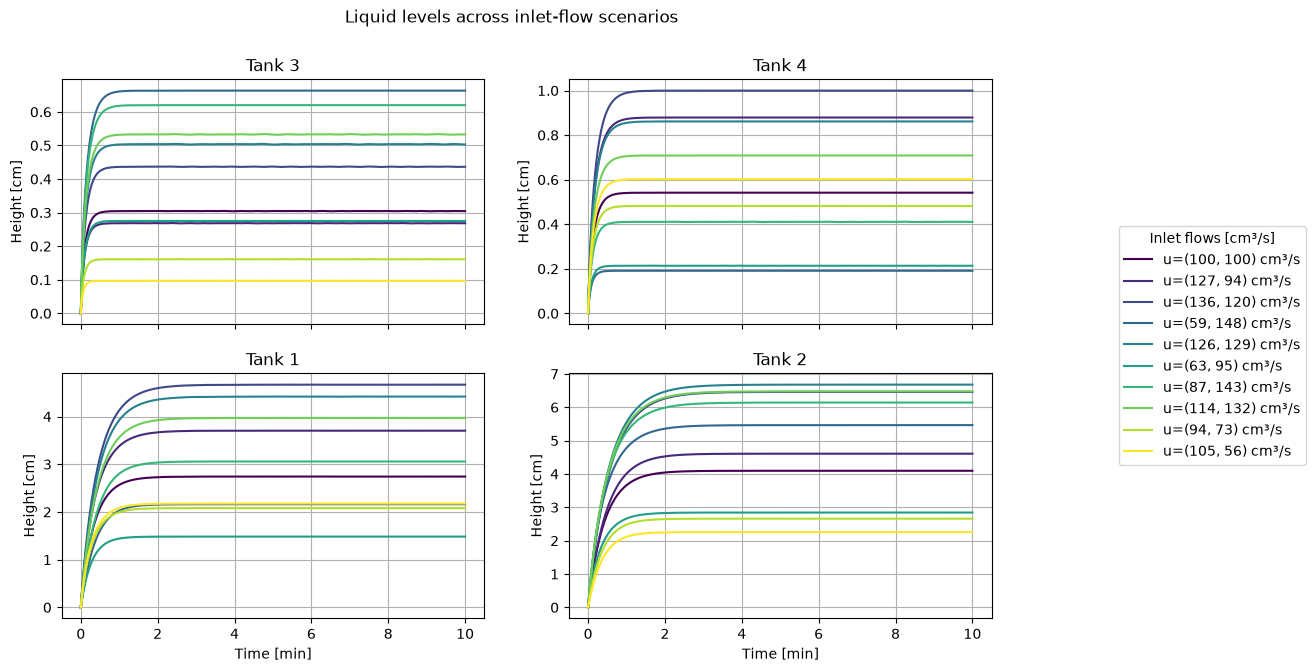

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
axes = axes.ravel()
tank_order = [2, 3, 0, 1]

colors = plt.cm.viridis(np.linspace(0, 1, n_scenarios))

for scenario, (heights, u_i, color) in enumerate(
    zip(trajectories, u_scenarios, colors)
):
    label = f"u=({u_i[0]:.0f}, {u_i[1]:.0f}) cm³/s"

    for ax, i in zip(axes, tank_order):
        ax.plot(
            tspan / 60,
            heights[i],
            color=color,
            label=label,
        )

for ax, i in zip(axes, tank_order):
    ax.set_title(f"Tank {i + 1}")
    ax.set_ylabel("Height [cm]")
    ax.grid(True)

for ax in axes[2:]:
    ax.set_xlabel("Time [min]")

# Use one shared legend rather than repeating it in every panel.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title="Inlet flows [cm³/s]",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
)

fig.suptitle("Liquid levels across inlet-flow scenarios")
plt.show()

The plots show how the heights in the four tanks change with time. The different inlet conditions determines how full each tank becomes. They all reach steady state well within the given time frame.

To train the PINN, "measurements" are obtained from the data as tank levels. It is assumed that measurements can be taken every 1 seconds. It is assumed there is no noise on the measurment data.

Now the PINN is defined using the same definition as in the Lecture slides

In [32]:
# Parameters
n_neurons = 50 # hidden nodes in each layer
lr = 0.01 # learning rate, optimizer
criterion = nn.MSELoss()
n_epochs = 5000 # total epoch to train

Claude has been used to modify the PINN class slightly, as some of the functions in the lecture slides where outdated.

Furthermore, it suggested to implement gamma as an parameter directly in the PINN, as the algortithm is thereby able to tune these values while tuning the weights and biases of the system.

In [33]:
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(
        nn.Linear(3, n_neurons), nn.Tanh(), # Inputs are time and inlet flows
        nn.Linear(n_neurons, n_neurons),nn.Tanh(),
        nn.Linear(n_neurons,n_neurons),nn.Tanh(),
        nn.Linear(n_neurons,n_neurons),nn.Tanh(),
        nn.Linear(n_neurons,4), # Four states to output
        )
        # unknown valve positions, kept in (0,1) via sigmoid
        self.gamma_raw = nn.Parameter(torch.zeros(2))   # sigmoid(0) = 0.5 initial guess

    # This code was proposed by Claude, to construct the PINN to be parameter estimating
    # Add the property which should be learned to the nn:
    @property
    def gamma(self):
        return torch.sigmoid(self.gamma_raw) # Use sigmoid as gamma must be between 0 and 1


    # forward method
    def forward(self, tau, u_norm):
        # 1 time + 2 flows
        features = torch.cat((tau, u_norm), dim=1)
        return tau * self.body(features)


net = PINN().to(device)
print(net.gamma)
# As gamma is defined in the nn, this is a part of net.parameters(),
# and will be updated together with the weights (explained by Claude)
optimizer = optim.Adam(net.parameters(), lr=lr)
p_t = torch.as_tensor(p)


tensor([0.5000, 0.5000], grad_fn=<SigmoidBackward0>)


The residuals are calculated in the col points. In order to do so, the diff equation must be defined in torch variables:

In [34]:
def four_tank_rhs_torch(x, u, gamma, p): 
    # Unpack parameters
    a = p[0:4]       # Pipe cross-sectional areas [cm^2]
    A = p[4:8]       # Tank cross-sectional areas [cm^2]
    g = p[10]        # Acceleration of gravity [cm/s^2]
    rho = p[11]      # Water density [g/cm^3]

    qin = torch.stack([
        gamma[0] * u[:, 0],
        gamma[1] * u[:, 1],
        (1 - gamma[1]) * u[:, 1],
        (1 - gamma[0]) * u[:, 0],
    ], dim=1)                                       # (n, 4)

    # make differentiable (this is more robust that forcing x to be positive)
    h = torch.clamp(x / (rho * A), min=1e-6) 
    qout = a * torch.sqrt(2 * g * h)

    return rho * torch.stack([
        qin[:, 0] + qout[:, 2] - qout[:, 0],
        qin[:, 1] + qout[:, 3] - qout[:, 1],
        qin[:, 2] - qout[:, 2],
        qin[:, 3] - qout[:, 3],
    ], dim=1)

The residuals are computed using code from the Lecture slide, which again was slightly modified by Claude to update some functions

In [35]:
def compute_residuals(tau, u_norm):
    z = net(tau, u_norm) # scaled states (n,7)
    z_tau = torch.cat([
        torch.autograd.grad(
            z[:, i:i+1],
            tau,
            grad_outputs=torch.ones_like(z[:, i:i+1]),
            create_graph=True,
        )[0]
        for i in range(4)
    ], dim=1)    # dz/dtau

    x = z * m_scale        # physical mass [g]
    u = u_norm * u_scale
    f = four_tank_rhs_torch(x, u, net.gamma, p_t)  # [g/s]

    # dz/dtau = (t_scale / m_scale) * f   ->  non-dimensional residual
    return z_tau - t_scale * f / m_scale

The training algorithm from the Lecture slides is modified to fit traning on each scenario.
Furthermore, the physics loss is weighted, as it was seen that during training, this loss was much higher than the data loss, meaning this loss "overruled" the data loss. This made the PINN unable to fit to the measurement points. The weighting factor lambda_f was chosen by trial and error. Here a further split in training and validation set could also have been used.

In [36]:
lambda_f = 1e-4  # Check the data and weighted physics losses separately.
n_phys = 3000

for epoch in range(n_epochs):
    optimizer.zero_grad()

    h_pred = net(tau_b, u_b)
    loss_data = criterion(h_pred, h_b)

    scenario_idx = torch.randint(n_scenarios, (n_phys,), device=device)
    tau_f = torch.rand(n_phys, 1, device=device, requires_grad=True)

    residual = compute_residuals(
        tau_f,
        u_scenarios_t[scenario_idx])
    loss_physics = criterion(residual, torch.zeros_like(residual))

    loss = loss_data + lambda_f * loss_physics
    
    loss.backward()
    optimizer.step()

The gamma values obtained by the PINN are found:

In [14]:
print(net.gamma)

tensor([0.6046, 0.7038], grad_fn=<SigmoidBackward0>)


It is seen that the PINN is able to identify the "unknown" parameters. However, for real usage of the PINN algorithm, these will not be known, so in order to evaluate if the parameters are estimated correctly, one must evaluate hoe well the PINN estimates the measurements. This is initially seen for the training scenarios:

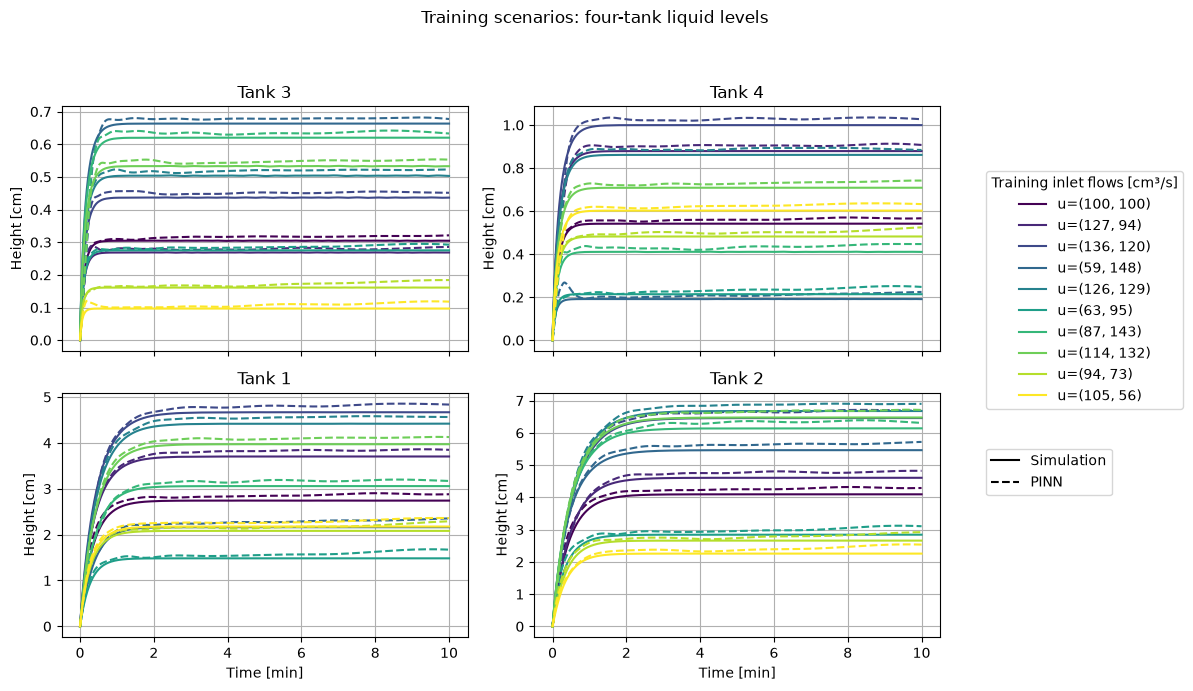

In [37]:
# Predict each training scenario with its own inlet-flow condition.
net.eval()
with torch.no_grad():
    h_nn_train = []
    for s in range(n_scenarios):
        u_input = u_scenarios_t[s:s+1].expand(n_time, -1)

        # Network output is normalized height; scale back to cm.
        h_pred = net(tau_plot, u_input) * h_max
        h_nn_train.append(h_pred.cpu().numpy().T)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
axes = axes.ravel()
tank_order = [2, 3, 0, 1]
time_min = tspan / 60
sample_time_min = tspan[measurement_idx] / 60

for ax, tank_i in zip(axes, tank_order):
    for s in range(n_scenarios):
        color = colors[s]
        u_i = u_scenarios[s]
        label = f"u=({u_i[0]:.0f}, {u_i[1]:.0f})"

        # Simulated reference trajectory.
        ax.plot(
            time_min,
            trajectories[s][tank_i],
            color=color,
            label=label if tank_i == tank_order[0] else None,
        )

        # PINN prediction for this scenario.
        ax.plot(
            time_min,
            h_nn_train[s][tank_i],
            "--",
            color=color,
        )


    ax.set_title(f"Tank {tank_i + 1}")
    ax.set_ylabel("Height [cm]")
    ax.grid(True)

for ax in axes[2:]:
    ax.set_xlabel("Time [min]")

# Scenario colors and line styles are explained separately.
scenario_handles, scenario_labels = axes[0].get_legend_handles_labels()
fig.legend(
    scenario_handles,
    scenario_labels,
    title="Training inlet flows [cm³/s]",
    loc="center left",
    bbox_to_anchor=(0.82, 0.58),
)

style_handles = [
    Line2D([0], [0], color="black", linestyle="-", label="Simulation"),
    Line2D([0], [0], color="black", linestyle="--", label="PINN"),
    #Line2D([0], [0], color="black", marker="o", linestyle="None", markersize=5, label="Training samples"),
]
fig.legend(
    handles=style_handles,
    loc="center left",
    bbox_to_anchor=(0.82, 0.32),
)

fig.suptitle("Training scenarios: four-tank liquid levels")
fig.tight_layout(rect=[0, 0, 0.8, 0.94])
plt.show()


It is seen that the PINN can reasonably fit to the training data, which indicates that the unknown parameters are estimated sufficiently. It shows better estimation for tank 1 and 2, than for tank 3 and 4, where it tends to overshoot the heights in the beginning of the simulation. This might give problems, if the PINN should be used together with a control algortihm, as it could lead to agressive control action. However, for tank 1 and 2, this does not seem to be a problem. It does also show a tendency to overestimate the heights in all the tanks. Perhaps the number of epochs should be higher. This could also be improved by using a validation dataset, to tune these hyperparameters.

Now the PINN is be tested on unseen data, with new values of inlet flowrates. Three scenarios are tested, one indside the training range, one below and one above. The three true trajectories are found by solving the IVP and the PINN estimation are found for all three.

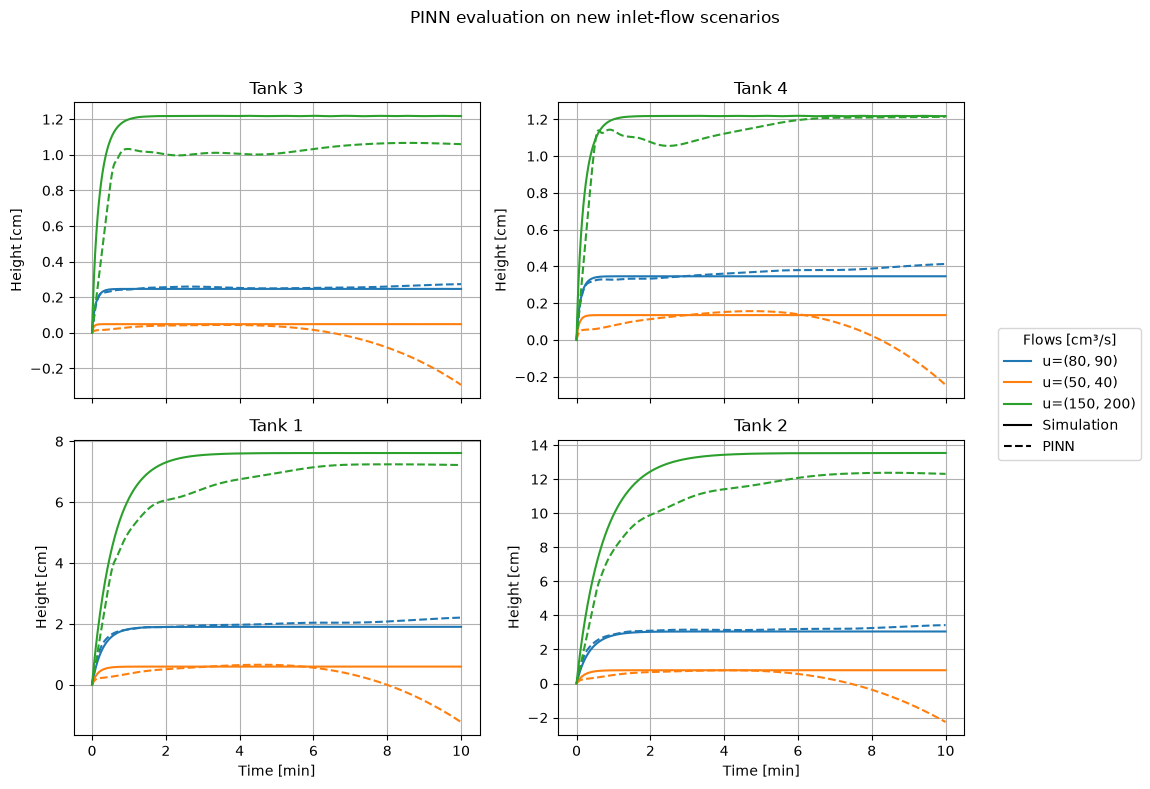

u=(np.float64(80.0), np.float64(90.0)): height MSE = 0.013096 cm²
u=(np.float64(50.0), np.float64(40.0)): height MSE = 0.329968 cm²
u=(np.float64(150.0), np.float64(200.0)): height MSE = 0.949303 cm²


In [38]:
# New evaluation flows: one inside the training range, two outside.
u_test_scenarios = np.array([
    [80.0, 90.0],
    [50.0, 40.0],
    [150.0, 200.0],
])

tau_test_plot = torch.as_tensor(
    tspan / t_scale, dtype=torch.float32, device=device
).reshape(-1, 1)

test_trajectories = []
test_predictions = []

# Predict each training scenario with its own inlet-flow condition.
net.eval()
with torch.no_grad():
    for u_i in u_test_scenarios:
        # Simulator reference trajectory: convert mass to height.
        sol_test = solve_ivp(
            four_tank_system,
            (tspan[0], tspan[-1]),
            x0,
            t_eval=tspan,
            args=(u_i, p),
        )
        if not sol_test.success:
            raise RuntimeError(sol_test.message)

        h_reference = sol_test.y / rhoA.reshape(4, 1)
        test_trajectories.append(h_reference)

        # Condition the PINN on this flow, normalized using training scales.
        u_i_norm = (
            torch.as_tensor(u_i, dtype=torch.float32, device=device) / u_scale
        )
        u_input = u_i_norm.reshape(1, 2).expand(len(tspan), -1)

        h_pred_norm = net(tau_test_plot, u_input)
        h_prediction = (h_pred_norm * h_max).cpu().numpy().T
        test_predictions.append(h_prediction)

# Compare simulation and PINN predictions for all four tanks.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
axes = axes.ravel()
tank_order = [2, 3, 0, 1]
colors = plt.cm.tab10(np.arange(len(u_test_scenarios)))

for ax, tank_i in zip(axes, tank_order):
    for scenario_i, u_i in enumerate(u_test_scenarios):
        label = f"u=({u_i[0]:.0f}, {u_i[1]:.0f}) cm³/s"
        color = colors[scenario_i]

        ax.plot(
            tspan / 60,
            test_trajectories[scenario_i][tank_i],
            color=color,
            label=label,
        )
        ax.plot(
            tspan / 60,
            test_predictions[scenario_i][tank_i],
            "--",
            color=color,
        )

    ax.set_title(f"Tank {tank_i + 1}")
    ax.set_ylabel("Height [cm]")
    ax.grid(True)

for ax in axes[2:]:
    ax.set_xlabel("Time [min]")

scenario_handles = [
    Line2D([0], [0], color=colors[i], label=f"u=({u[0]:.0f}, {u[1]:.0f})")
    for i, u in enumerate(u_test_scenarios)
]
style_handles = [
    Line2D([0], [0], color="black", linestyle="-", label="Simulation"),
    Line2D([0], [0], color="black", linestyle="--", label="PINN"),
]

fig.legend(
    handles=scenario_handles + style_handles,
    loc="center left",
    bbox_to_anchor=(0.83, 0.5),
    title="Flows [cm³/s]",
)
fig.suptitle("PINN evaluation on new inlet-flow scenarios")
fig.tight_layout(rect=[0, 0, 0.82, 0.95])
plt.show()

# Report errors per scenario in physical height units.
for u_i, h_reference, h_prediction in zip(
    u_test_scenarios, test_trajectories, test_predictions
):
    mse_cm2 = np.mean((h_prediction - h_reference) ** 2)
    print(f"u={tuple(u_i)}: height MSE = {mse_cm2:.6f} cm²")

The plots show that the PINN is nicely able to follow the trajectory for the scenario which falls inside the traning range. However, the two scenarios outisde the training range are less accurate. Especially the lower scenario gives troubles for the PINN. It is seen that is is not able to understand the physics of the steady state solution. To mitigate this, the PINN should be trained on data with lower inlet flows, or perhaps trained on data, where the inlet flows vary, e.g. starting from zero and then being turned on.

The scenario of higher flowrates perform better, however the PINN clearly undestimate the heights.

This shows that even though the PINN was nicely able to tune the unknown parameters, it still struggled with clearly following the physics of the system.